# Exercise 1

In [1]:
import numpy as np

In [2]:
def generate_stripe_image(size, stripe_nr, vertical = True):
  img=np.zeros((size,size,1),dtype="uint8")
  for i in range(0,stripe_nr):
    x,y = np.random.randint(0,size,2)
    l  = np.random.randint(y,size,1).item()
    if (vertical):
      img[y:l,x,0]=255
    else:
      img[x,y:l,0]=255
  return img  

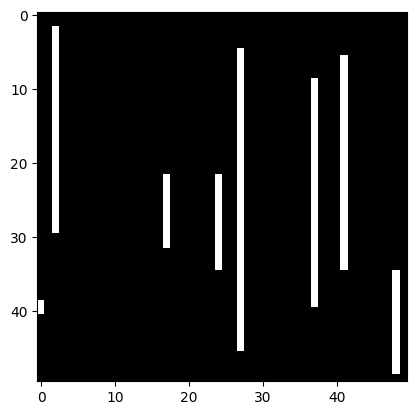

In [3]:
import matplotlib.pyplot as plt
import numpy as np

img=generate_stripe_image(50,10, vertical=True)
plt.imshow(img[:,:,0],cmap='gray')


# 1.1

In [4]:
size = 50
stripe_nr = 10
X_train = np.stack(
    [generate_stripe_image(size, stripe_nr, vertical=True) for _ in range(500)] +
    [generate_stripe_image(size, stripe_nr, vertical=False) for _ in range(500)]
)  / 255
X_val = np.stack(
    [generate_stripe_image(size, stripe_nr, vertical=True) for _ in range(500)] +
    [generate_stripe_image(size, stripe_nr, vertical=False) for _ in range(500)]
)  / 255

# 1.2

In [5]:
from tensorflow.keras.utils import to_categorical
Y_train = np.array([0 for _ in range(500)] + [1 for _ in range(500)])
Y_val = np.array([0 for _ in range(500)] + [1 for _ in range(500)])

Y_train, Y_val = to_categorical(Y_train), to_categorical(Y_val)

# 1.3

In [18]:
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

# Model
model = Sequential()

model.add(layers.Conv2D(filters=1, kernel_size=(5,5), activation='relu', input_shape=(50,50,1)))
model.add(layers.MaxPooling2D(pool_size=(50,50), padding='same'))
model.add(layers.Flatten())
model.add(layers.Dense(2, activation='softmax'))
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 46, 46, 1)      │            26 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 1, 1, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30 (120.00 B)

 Trainable params: 30 (120.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 1.4

In [ ]:
history=model.fit(X_train, Y_train,
                  validation_data=(X_val,Y_val),
                  batch_size=64, 
                  epochs=50,
                  verbose=1,
                  shuffle=True) 

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5000 - loss: 0.7262 - val_accuracy: 0.5000 - val_loss: 0.7137
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5000 - loss: 0.7038 - val_accuracy: 0.5000 - val_loss: 0.6949
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5000 - loss: 0.6869 - val_accuracy: 0.5000 - val_loss: 0.6797
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5000 - loss: 0.6731 - val_accuracy: 0.5000 - val_loss: 0.6673
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5000 - loss: 0.6613 - val_accuracy: 0.5000 - val_loss: 0.6562
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5000 - loss: 0.6502 - val_accuracy: 0.5000 - val_loss: 0.6450
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5000 - loss: 0.6385 - val_accuracy: 0.5000 - val_loss: 0.6328
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5280 - loss: 0.6255 - val_accuracy: 0.5370 - v

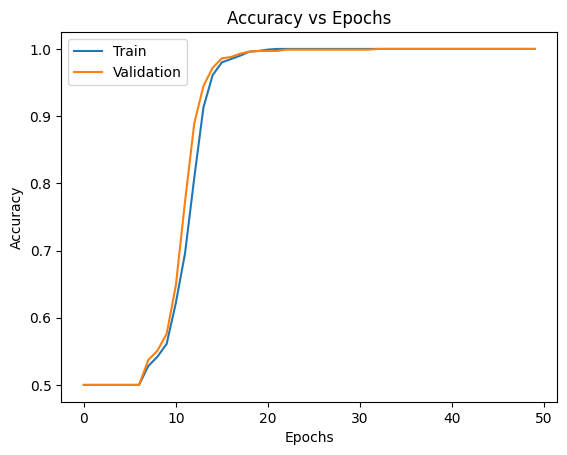

In [9]:
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

plt.figure()
plt.plot(range(len(accuracy)), accuracy)
plt.plot(range(len(val_accuracy)), val_accuracy)
plt.title("Accuracy vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

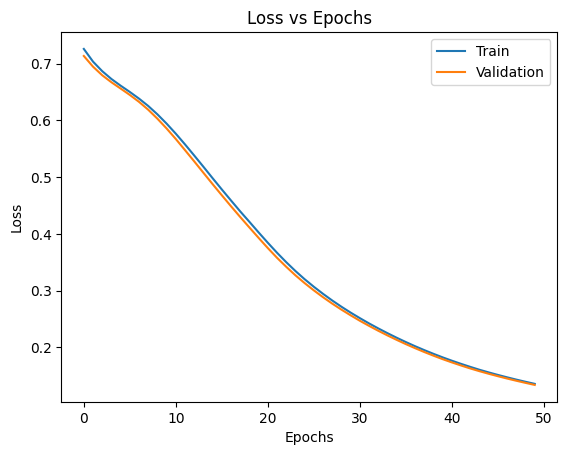

In [10]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure()
plt.plot(range(len(loss)), loss)
plt.plot(range(len(val_loss)), val_loss)
plt.title("Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

# 1.5

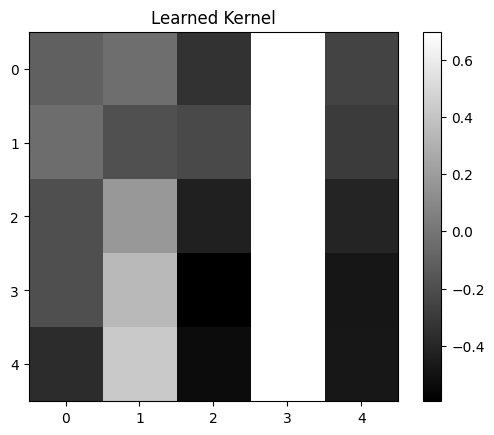

In [11]:
conv_filter=model.get_weights()[0]
my_kernel = conv_filter[:, :, 0, 0]
plt.imshow(my_kernel, cmap='gray')
plt.colorbar()
plt.title("Learned Kernel")
plt.show()

The kernel is made of 5x5 grayscale pixels.
It doesen't seem reasonable for the kernel to distinguish horizontal and vertical stripes because there is no appearent pattern in the kernel.

# 1.6

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 46, 46, 1)      │            26 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 1, 1, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30 (120.00 B)

 Trainable params: 30 (120.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5000 - loss: 0.7111 - val_accuracy: 0.5000 - val_loss: 0.6832
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5000 - loss: 0.6721 - val_accuracy: 0.5000 - val_loss: 0.6483
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5000 - loss: 0.6396 - val_accuracy: 0.5000 - val_loss: 0.6214
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5000 - loss: 0.6149 - val_accuracy: 0.5000 - val_loss: 0.5989
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5000 - loss: 0.5935 - val_accuracy: 0.5000 - val_loss: 0.5794
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5030 - loss: 0.5738 - val_accuracy: 0.5070 - val_loss: 0.5608
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5110 - loss: 0.5551 - val_accuracy: 0.5150 - val_loss: 0.5427
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5220 - loss: 0.5371 - val_accuracy: 0.5340 - v

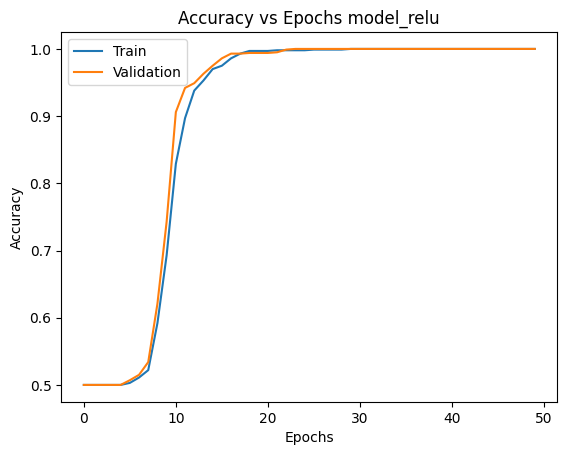

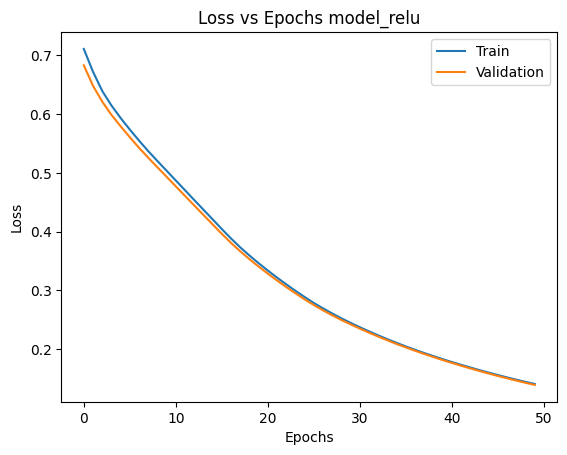

In [14]:
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

# Model
model_relu = Sequential()

model_relu.add(layers.Conv2D(filters=1, kernel_size=(5,5), activation='relu', input_shape=(50,50,1)))
model_relu.add(layers.MaxPooling2D(pool_size=(50,50), padding='same'))
model_relu.add(layers.Flatten())
model_relu.add(layers.Dense(2, activation='softmax'))
model_relu.summary()

# Compile
model_relu.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history=model_relu.fit(X_train, Y_train,
                  validation_data=(X_val,Y_val),
                  batch_size=64, 
                  epochs=50,
                  verbose=1,
                  shuffle=True) 

accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

plt.figure()
plt.plot(range(len(accuracy)), accuracy)
plt.plot(range(len(val_accuracy)), val_accuracy)
plt.title("Accuracy vs Epochs model_relu")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure()
plt.plot(range(len(loss)), loss)
plt.plot(range(len(val_loss)), val_loss)
plt.title("Loss vs Epochs model_relu")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

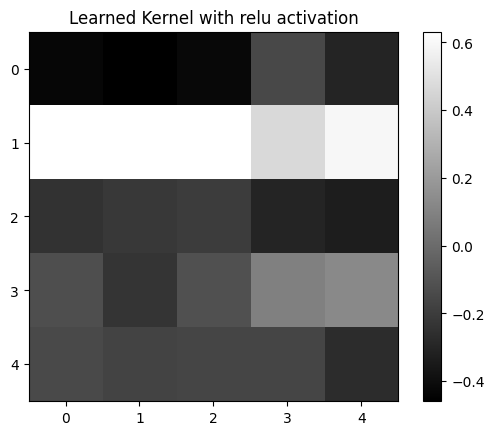

In [15]:
conv_filter=model_relu.get_weights()[0]
my_kernel = conv_filter[:, :, 0, 0]
plt.imshow(my_kernel, cmap='gray')
plt.colorbar()
plt.title("Learned Kernel with relu activation")
plt.show()

With relu activation, we have the same accuracy of 1 on the validation set but the kernel's appearence changed.

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 46, 46, 1)      │            26 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 1, 1, 1)        │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30 (120.00 B)

 Trainable params: 30 (120.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5010 - loss: 0.6750 - val_accuracy: 0.5000 - val_loss: 0.6738
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5000 - loss: 0.6722 - val_accuracy: 0.5000 - val_loss: 0.6709
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5480 - loss: 0.6692 - val_accuracy: 0.7430 - val_loss: 0.6680
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9480 - loss: 0.6662 - val_accuracy: 0.9990 - val_loss: 0.6650
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.6631 - val_accuracy: 0.9990 - val_loss: 0.6619
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9990 - loss: 0.6600 - val_accuracy: 0.9980 - val_loss: 0.6588
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9990 - loss: 0.6568 - val_accuracy: 0.9980 - val_loss: 0.6556
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9970 - loss: 0.6535 - val_accuracy: 0.9980 - v

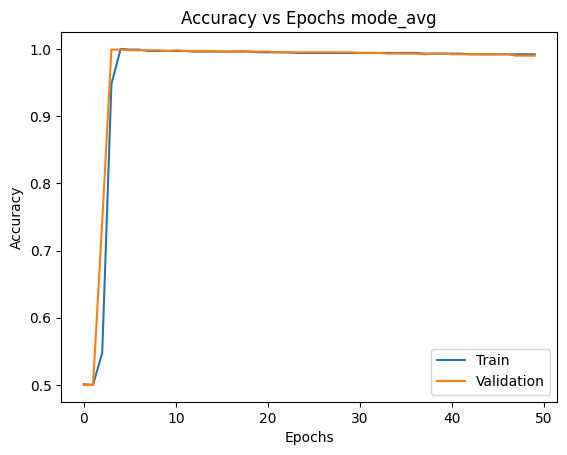

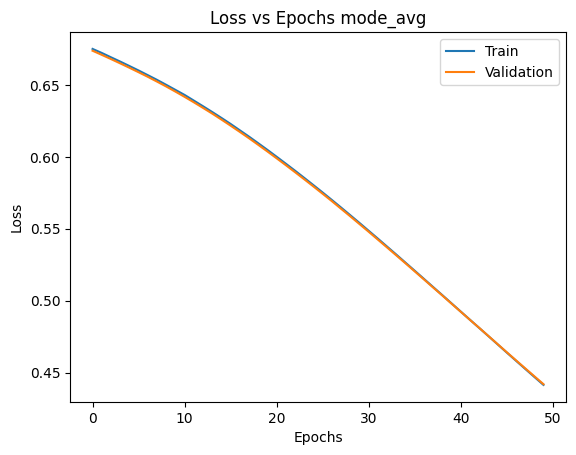

In [16]:
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

# Model
mode_avg = Sequential()

mode_avg.add(layers.Conv2D(filters=1, kernel_size=(5,5), activation='relu', input_shape=(50,50,1)), )
mode_avg.add(layers.AveragePooling2D(pool_size=(50,50), padding='same'))
mode_avg.add(layers.Flatten())
mode_avg.add(layers.Dense(2, activation='softmax'))
mode_avg.summary()

# Compile
mode_avg.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history=mode_avg.fit(X_train, Y_train,
                  validation_data=(X_val,Y_val),
                  batch_size=64, 
                  epochs=50,
                  verbose=1,
                  shuffle=True) 

accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

plt.figure()
plt.plot(range(len(accuracy)), accuracy)
plt.plot(range(len(val_accuracy)), val_accuracy)
plt.title("Accuracy vs Epochs mode_avg")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure()
plt.plot(range(len(loss)), loss)
plt.plot(range(len(val_loss)), val_loss)
plt.title("Loss vs Epochs mode_avg")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

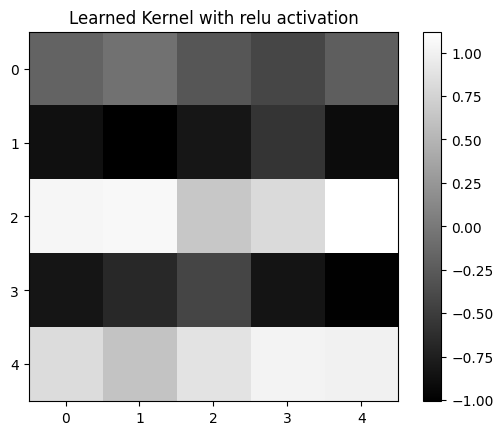

In [17]:
conv_filter=mode_avg.get_weights()[0]
my_kernel = conv_filter[:, :, 0, 0]
plt.imshow(my_kernel, cmap='gray')
plt.colorbar()
plt.title("Learned Kernel with relu activation")
plt.show()

With average pooling, we have the same accuracy of 1 on the validation set but the kernel's appearence changed and th accuracy reaches 1 more quickly.